# Bài 5 (trang 29, mục V.5) - Gom cụm Breast Cancer Wisconsin bằng K-Means

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Gom cụm dữ liệu tế bào ung thư vú với K-Means k=2, đối chiếu kết quả với nhãn benign/malignant có sẵn và đánh giá bằng các độ đo phân lớp.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             classification_report, silhouette_score)
from scipy.optimize import linear_sum_assignment

print("Nguyễn Đức Vinh - MSSV: 6451071087")

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Đọc bộ dữ liệu Breast Cancer Wisconsin (Diagnostic)

In [2]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.to_numpy(dtype=float)
y = cancer.target  # sklearn: 0 = malignant, 1 = benign
class_names = np.array(cancer.target_names)
print("Kích thước dữ liệu:", X.shape)
print("Tên thuộc tính:", list(cancer.feature_names))
print("Nhãn lớp:", class_names)
print("Số mẫu mỗi lớp:")
print(pd.Series(y).map({i: class_names[i] for i in range(2)}).value_counts())
display(cancer.frame.head())
print("Giá trị thiếu:", int(cancer.frame.isna().sum().sum()))

Nguyễn Đức Vinh - MSSV: 6451071087
Kích thước dữ liệu: (569, 30)
Tên thuộc tính: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]
Nhãn lớp: ['malignant' 'benign']
Số mẫu mỗi lớp:
target
benign       357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Giá trị thiếu: 0


## 3. Chuẩn hóa và gom cụm K-Means với k=2

In [3]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=2, init="k-means++", n_init=20,
                random_state=42, max_iter=300)
cluster_ids = kmeans.fit_predict(X_scaled)
print("Inertia:", kmeans.inertia_)
print("Silhouette:", round(float(silhouette_score(X_scaled, cluster_ids)), 4))

Nguyễn Đức Vinh - MSSV: 6451071087
Inertia: 11595.461473962348
Silhouette: 0.345


## 4. Ánh xạ nhãn cụm và đánh giá

Nguyễn Đức Vinh - MSSV: 6451071087
Mapping cluster -> class: {0: 0, 1: 1}
Accuracy sau ánh xạ: 0.9104
              precision    recall  f1-score   support

   malignant     0.9259    0.8255    0.8728       212
      benign     0.9026    0.9608    0.9308       357

    accuracy                         0.9104       569
   macro avg     0.9143    0.8931    0.9018       569
weighted avg     0.9113    0.9104    0.9092       569



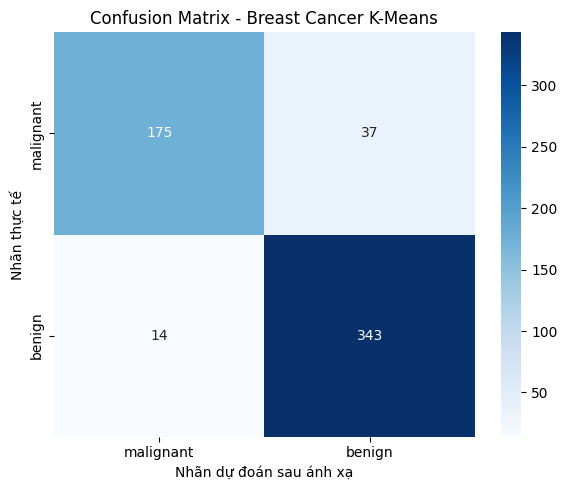

In [4]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
# Ánh xạ hai mã cụm về benign/malignant bằng Hungarian algorithm.
contingency = confusion_matrix(y, cluster_ids, labels=np.arange(2))
row_ind, col_ind = linear_sum_assignment(-contingency)
cluster_to_class = {int(cluster): int(actual) for actual, cluster in zip(row_ind, col_ind)}
predicted_class = np.array([cluster_to_class[int(c)] for c in cluster_ids])

cm = confusion_matrix(y, predicted_class, labels=np.arange(2))
print("Mapping cluster -> class:", cluster_to_class)
print("Accuracy sau ánh xạ:", round(accuracy_score(y, predicted_class), 4))
print(classification_report(y, predicted_class, labels=np.arange(2),
                            target_names=class_names, digits=4, zero_division=0))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Nhãn dự đoán sau ánh xạ")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - Breast Cancer K-Means")
plt.tight_layout()
plt.show()

## 5. Trực quan hóa kết quả bằng PCA

Nguyễn Đức Vinh - MSSV: 6451071087


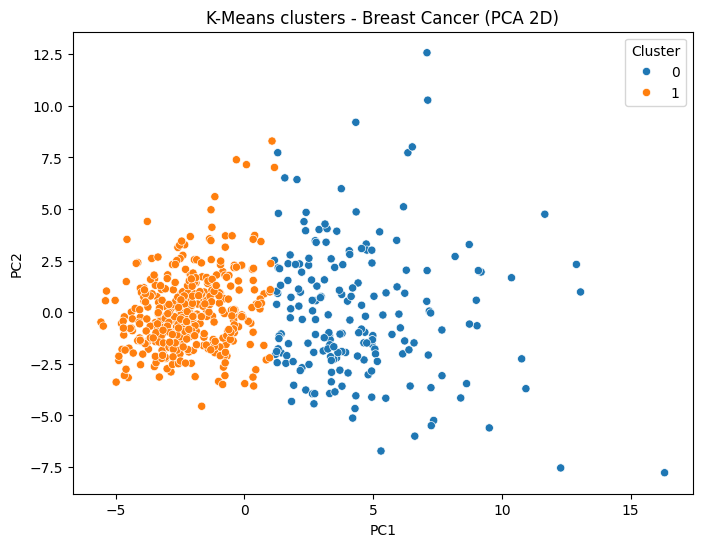

Tỷ lệ phương sai giải thích bởi 2 thành phần PCA: 0.6324


In [5]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": cluster_ids.astype(str),
    "Actual class": [class_names[int(v)] for v in y]
})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", s=35)
plt.title("K-Means clusters - Breast Cancer (PCA 2D)")
plt.show()
print("Tỷ lệ phương sai giải thích bởi 2 thành phần PCA:",
      round(float(pca.explained_variance_ratio_.sum()), 4))

## 6. Nhận xét

K-Means không sử dụng nhãn benign/malignant khi huấn luyện. Nhãn thật chỉ được dùng sau đó để ánh xạ mã cụm và đánh giá. Các chỉ số phân lớp sau ánh xạ giúp định lượng mức tương đồng, nhưng không biến mô hình gom cụm thành công cụ chẩn đoán y tế; kết quả chỉ phục vụ mục đích học thuật.